In [ ]:
#
#
#
# Link para o Dataset: https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data?resource=download
#
#
#


In [ ]:
# Imports

import pandas as pd
from google.colab import files
arquivos = files.upload()

Saving loan_data.csv to loan_data.csv


In [ ]:
# Leitura e limpeza dos dados

dados = pd.read_csv("loan_data.csv")

# Define uma regra de plausibilidade para este projeto.
IDADE_MAXIMA = 100
TEMPO_SERVICO_MAXIMO = 60


def limpar_dados(df, idade_maxima=IDADE_MAXIMA, tempo_servico_maximo=TEMPO_SERVICO_MAXIMO):
    print("Quantidade de dados antes da limpeza")
    print("Registros:", df.shape[0])
    print("Colunas:", df.shape[1])
    print("\nValores nulos:", df.isnull().sum().sum())
    print("Registros duplicados:", df.duplicated().sum())

    idade_acima = df["person_age"] > idade_maxima
    servico_acima = df["person_emp_exp"] > tempo_servico_maximo

    print("\nRegistros com idade acima de", idade_maxima, "anos:", idade_acima.sum())
    print("Registros com tempo de serviço acima de", tempo_servico_maximo, "anos:", servico_acima.sum())
    print("Registros que se encaixam nos dois critérios:", (idade_acima & servico_acima).sum())

    invalidos = idade_acima | servico_acima

    print("\nRegistros que serão removidos:")
    display(df.loc[invalidos])

    df_limpo = df.loc[~invalidos].copy()

    print("Quantidade original:", len(df))
    print("Quantidade removida:", invalidos.sum())
    print("Quantidade após a limpeza:", len(df_limpo))

    print("\nMaiores valores após a limpeza:")
    print(df_limpo[["person_age", "person_emp_exp"]].max())

    return df_limpo

dados = pd.read_csv("loan_data.csv")
dados_limpos = limpar_dados(dados)

Quantidade de dados antes da limpeza
Registros: 45000
Colunas: 14

Valores nulos: 0
Registros duplicados: 0

Registros com idade acima de 100 anos: 7
Registros com tempo de serviço acima de 60 anos: 10
Registros que se encaixam nos dois critérios: 7

Registros que serão removidos:


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
81,144.0,male,Bachelor,300616.0,125,RENT,4800.0,VENTURE,13.57,0.02,3.0,789,No,0
183,144.0,male,Associate,241424.0,121,MORTGAGE,6000.0,EDUCATION,11.86,0.02,2.0,807,No,0
575,123.0,female,High School,97140.0,101,RENT,20400.0,EDUCATION,10.25,0.21,3.0,805,Yes,0
747,123.0,male,Bachelor,94723.0,100,RENT,20000.0,VENTURE,11.01,0.21,4.0,714,Yes,0
32297,144.0,female,Associate,7200766.0,124,MORTGAGE,5000.0,PERSONAL,12.73,0.00,25.0,850,No,0
32416,94.0,male,High School,29738.0,76,RENT,6500.0,MEDICAL,11.01,0.22,27.0,773,No,0
32422,80.0,male,High School,77894.0,62,RENT,6800.0,MEDICAL,11.71,0.09,25.0,673,No,0
32506,84.0,male,High School,114705.0,61,MORTGAGE,10000.0,PERSONAL,7.51,0.09,24.0,784,Yes,0
37930,116.0,male,Bachelor,5545545.0,93,MORTGAGE,3823.0,VENTURE,12.15,0.00,24.0,708,No,0
38113,109.0,male,High School,5556399.0,85,MORTGAGE,6195.0,VENTURE,12.58,0.00,22.0,792,No,0


Quantidade original: 45000
Quantidade removida: 10
Quantidade após a limpeza: 44990

Maiores valores após a limpeza:
person_age        78.0
person_emp_exp    58.0
dtype: float64


In [ ]:
# Colunas categóricas: lista cada rótulo e quantos registros possui
colunas_categoricas = ["person_gender", "person_education", "person_home_ownership", "loan_intent"]

for coluna in colunas_categoricas:
    print(f"\n=== {coluna} ===")
    print("Quantidade de rótulos:", dados_limpos[coluna].nunique())
    print(dados_limpos[coluna].value_counts())


=== person_gender ===
Quantidade de rótulos: 2
person_gender
male      24833
female    20157
Name: count, dtype: int64

=== person_education ===
Quantidade de rótulos: 5
person_education
Bachelor       13396
Associate      12026
High School    11967
Master          6980
Doctorate        621
Name: count, dtype: int64

=== person_home_ownership ===
Quantidade de rótulos: 4
person_home_ownership
RENT        23438
MORTGAGE    18484
OWN          2951
OTHER         117
Name: count, dtype: int64

=== loan_intent ===
Quantidade de rótulos: 6
loan_intent
EDUCATION            9151
MEDICAL              8546
VENTURE              7815
PERSONAL             7550
DEBTCONSOLIDATION    7145
HOMEIMPROVEMENT      4783
Name: count, dtype: int64


Registros no treino: 35992
Registros no teste: 8998

Proporção de aprovados no treino: 0.222
Proporção de aprovados no teste: 0.222
F1 médio na validação cruzada: 0.8261

Relatório de classificação (teste):
              precision    recall  f1-score   support

      Negado       0.93      0.98      0.95      6998
    Aprovado       0.90      0.76      0.82      2000

    accuracy                           0.93      8998
   macro avg       0.92      0.87      0.89      8998
weighted avg       0.93      0.93      0.93      8998



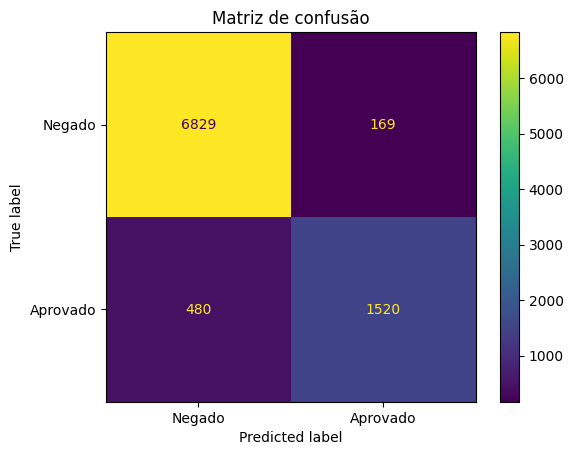

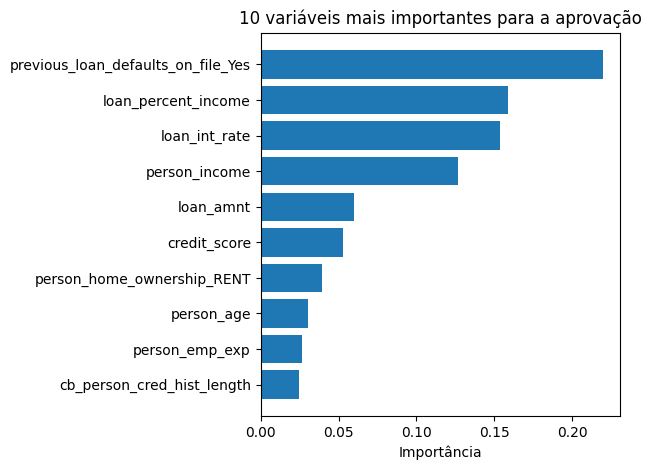

In [ ]:
import os
os.makedirs("imagens", exist_ok=True)
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Parâmetros do modelo
COLUNA_ALVO = "loan_status"   # 1 = aprovado, 0 = negado
TAMANHO_TESTE = 0.2           # 20% dos dados reservados para teste
SEMENTE = 42                  # deixa o resultado reproduzível
NUMERO_ARVORES = 200

def separar_treino_teste(df, coluna_alvo=COLUNA_ALVO, tamanho_teste=TAMANHO_TESTE, semente=SEMENTE):
    # X = características, y = classe (aprovado ou negado)
    X = df.drop(columns=[coluna_alvo])
    y = df[coluna_alvo]

    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=tamanho_teste, stratify=y, random_state=semente
    )

    print("Registros no treino:", len(X_treino))
    print("Registros no teste:", len(X_teste))
    print("\nProporção de aprovados no treino:", round(y_treino.mean(), 3))
    print("Proporção de aprovados no teste:", round(y_teste.mean(), 3))

    return X_treino, X_teste, y_treino, y_teste


X_treino, X_teste, y_treino, y_teste = separar_treino_teste(dados_limpos)

def criar_modelo(X, numero_arvores=NUMERO_ARVORES, semente=SEMENTE):
    colunas_texto = X.select_dtypes(include="object").columns
    colunas_numericas = X.select_dtypes(exclude="object").columns

    preprocessador = ColumnTransformer([
        ("texto", OneHotEncoder(drop="if_binary"), colunas_texto),
        ("numeros", "passthrough", colunas_numericas),
    ], verbose_feature_names_out=False)

    return Pipeline([
        ("preprocessamento", preprocessador),
        ("rf", RandomForestClassifier(n_estimators=numero_arvores, random_state=semente, n_jobs=-1)),
    ])


modelo = criar_modelo(X_treino)
modelo.fit(X_treino, y_treino)

def avaliar_modelo(modelo, X_treino, y_treino, X_teste, y_teste):
    # Validação cruzada nos dados de treino
    scores = cross_val_score(modelo, X_treino, y_treino, scoring="f1", cv=5, n_jobs=-1)
    print(f"F1 médio na validação cruzada: {scores.mean():.4f}")

    # Avaliação final nos dados de teste
    y_previsto = modelo.predict(X_teste)
    print("\nRelatório de classificação (teste):")
    print(classification_report(y_teste, y_previsto, target_names=["Negado", "Aprovado"]))

    ConfusionMatrixDisplay.from_predictions(
        y_teste, y_previsto, display_labels=["Negado", "Aprovado"]
    )
    plt.title("Matriz de confusão")
    plt.savefig("imagens/matriz_confusao.png", dpi=150, bbox_inches="tight")
    plt.show()


avaliar_modelo(modelo, X_treino, y_treino, X_teste, y_teste)

def mostrar_importancias(modelo, quantidade=10):
    nomes = modelo.named_steps["preprocessamento"].get_feature_names_out()
    importancias = modelo.named_steps["rf"].feature_importances_

    # Ordena da mais importante para a menos importante
    top = sorted(zip(nomes, importancias), key=lambda x: x[1], reverse=True)[:quantidade]

    plt.barh([n for n, _ in top][::-1], [i for _, i in top][::-1])
    plt.title(f"{quantidade} variáveis mais importantes para a aprovação")
    plt.xlabel("Importância")
    plt.tight_layout()
    plt.savefig("imagens/importancia_variaveis.png", dpi=150, bbox_inches="tight")
    plt.show()


mostrar_importancias(modelo)

In [ ]:
def prever_pessoa(modelo, pessoa):
    # O modelo espera uma tabela; aqui criamos uma com uma única linha
    tabela = pd.DataFrame([pessoa])

    classe = modelo.predict(tabela)[0]
    probabilidade = modelo.predict_proba(tabela)[0][1] # chance de ser aprovado

    print("Resultado:", "APROVADO" if classe == 1 else "NEGADO")
    print(f"Probabilidade de aprovação: {probabilidade:.1%}")


# Exemplo 1: perfil com boa chance de aprovação
pessoa_1 = {
    "person_age": 24,
    "person_gender": "male",
    "person_education": "High School",
    "person_income": 51609,
    "person_emp_exp": 1,
    "person_home_ownership": "RENT",
    "loan_amnt": 6665,
    "loan_intent": "DEBTCONSOLIDATION",
    "loan_int_rate": 17.05,
    "loan_percent_income": 0.13,
    "cb_person_cred_hist_length": 3,
    "credit_score": 628,
    "previous_loan_defaults_on_file": "No",
}

# Exemplo 2: perfil com risco maior
pessoa_2 = {
    "person_age": 22,
    "person_gender": "female",
    "person_education": "High School",
    "person_income": 20000,
    "person_emp_exp": 1,
    "person_home_ownership": "RENT",
    "loan_amnt": 15000,
    "loan_intent": "PERSONAL",
    "loan_int_rate": 16.0,
    "loan_percent_income": 0.75,
    "cb_person_cred_hist_length": 2,
    "credit_score": 520,
    "previous_loan_defaults_on_file": "Yes",
}

print("Pessoa 1")
prever_pessoa(modelo, pessoa_1)
print("\nPessoa 2")
prever_pessoa(modelo, pessoa_2)

Pessoa 1
Resultado: APROVADO
Probabilidade de aprovação: 95.5%

Pessoa 2
Resultado: NEGADO
Probabilidade de aprovação: 26.0%


In [ ]:
dados_limpos

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


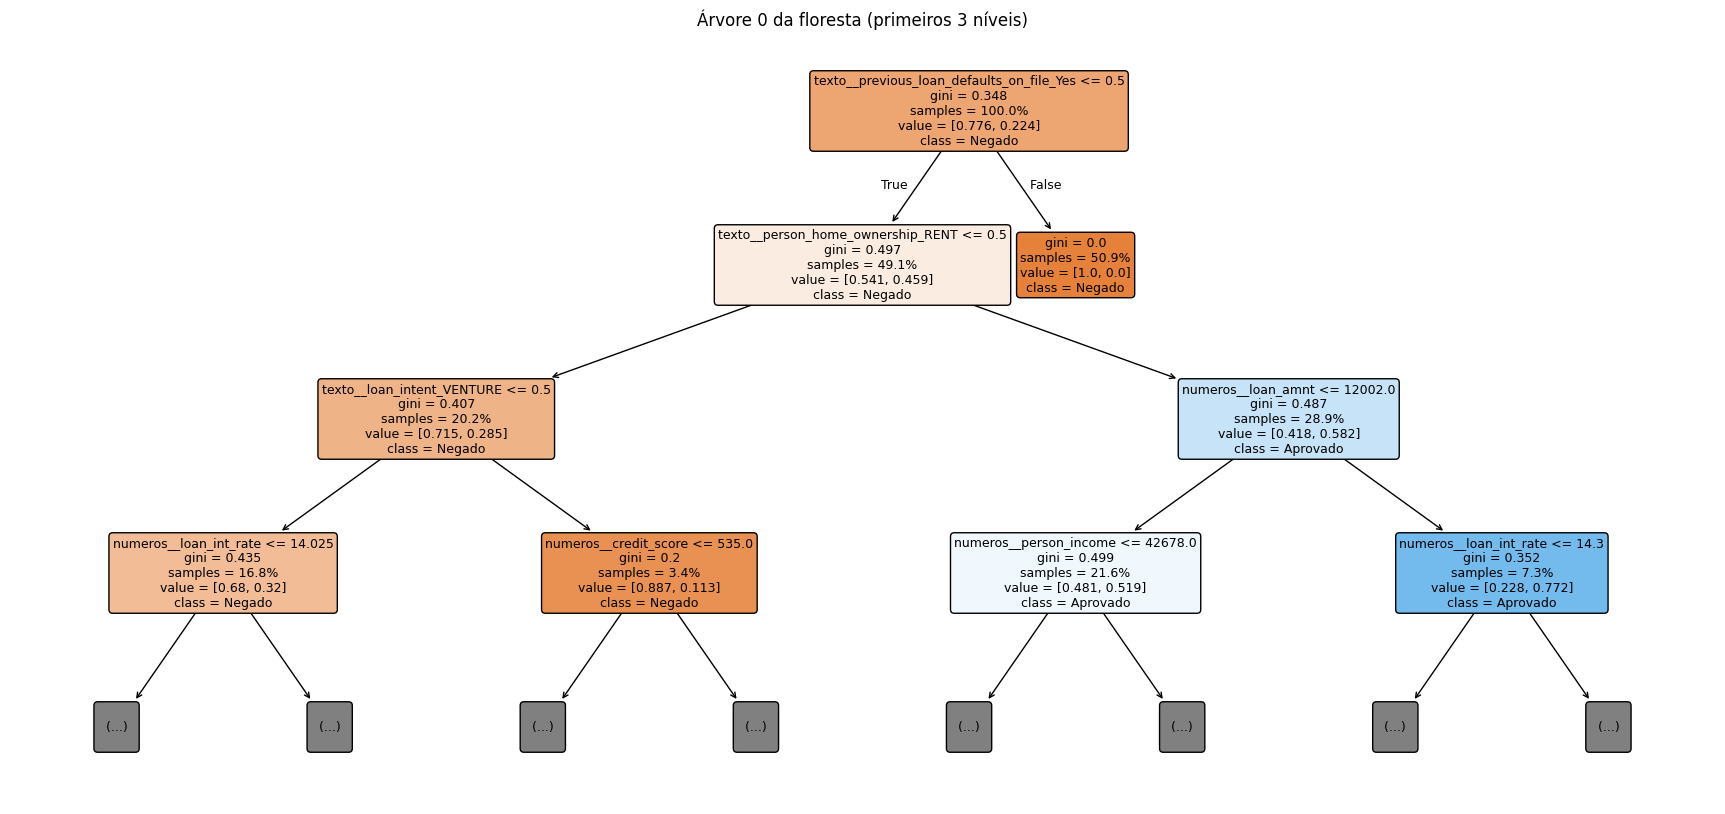

In [ ]:
from sklearn.tree import plot_tree

def mostrar_arvore(modelo, indice=0, profundidade=3):
    nomes = modelo.named_steps["preprocessamento"].get_feature_names_out()
    arvore = modelo.named_steps["rf"].estimators_[indice]

    plt.figure(figsize=(22, 10))
    plot_tree(
        arvore,
        feature_names=nomes,
        class_names=["Negado", "Aprovado"],
        max_depth=profundidade,
        filled=True,
        rounded=True,
        proportion=True,
        fontsize=9,
    )
    plt.title(f"Árvore {indice} da floresta (primeiros {profundidade} níveis)")
    plt.savefig(f"imagens/arvore_{indice}.png", dpi=150, bbox_inches="tight")
    plt.show()


mostrar_arvore(modelo)